# Palmer Penguins Modeling

Import the Palmer Penguins dataset and print out the first few rows.

Suppose we want to predict `species` using the other variables in the dataset.

**Dummify** all variables that require this.

In [1]:
!pip install palmerpenguins

In [2]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import *
from sklearn.tree import *
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import *
from palmerpenguins import load_penguins
from sklearn.preprocessing import *
from sklearn.compose import *
from sklearn.metrics import *
import numpy as np
from plotnine import ggplot, aes, geom_path, geom_abline, coord_equal, labs, theme_minimal
from IPython.display import display # Import display

penguins = load_penguins()
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [3]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [4]:
penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


Let's use the other variables to predict `species`. Prepare your data and fit the following models on the entire dataset:

* Two kNN models (for different values of K)
* Two decision tree models (for different complexities of trees)

Compute the following, for each of your models, on test data. Keep in mind that you may need to stratify your creation of the training and test data.

* Confusion matrix
* Overall Accuracy
* Precision, Recall, AUC, and F1-score for each species

Create one ROC plot for the species of your choice.

In [5]:
penguins = penguins.dropna()

In [6]:
X= penguins.drop(columns='species')
y= penguins['species']

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=321) #generally required for classifications

In [7]:
ct = ColumnTransformer([
    ("scalar", StandardScaler(), make_column_selector(dtype_include=np.number)),
    ("ohe", OneHotEncoder(drop="first", handle_unknown='ignore', sparse_output = False), make_column_selector(dtype_include=object))],
    remainder = 'passthrough'
).set_output(transform="pandas")

# Redefine scoring_classifier to remove the invalid 'roc_auc_ovr_macro' entry
scoring_classifier = {
    "ACC": "accuracy",
    "PREC_weighted": "precision_weighted",
    "REC_weighted": "recall_weighted",
    "F1_weighted": "f1_weighted",
    "PREC_macro": "precision_macro",
    "REC_macro": "recall_macro",
    "F1_macro": "f1_macro",
    "ROC_ovr_weighted": "roc_auc_ovr_weighted"
}

In [8]:
knn_pipe = Pipeline([
    ("ct", ct),
    ("knn", KNeighborsClassifier())
])

In [9]:
paraGrid = {
    'knn__n_neighbors': range(1, 10+1),
    'knn__metric': ['manhattan', 'euclidean']
}

search = GridSearchCV(knn_pipe, paraGrid, cv=CV, scoring=scoring_classifier, refit="ROC_ovr_weighted")
KNN_fit = search.fit(X, y)
pd.DataFrame(KNN_fit.cv_results_).sort_values(by='rank_test_ROC_ovr_weighted')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_knn__metric,param_knn__n_neighbors,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,...,std_test_F1_macro,rank_test_F1_macro,split0_test_ROC_ovr_weighted,split1_test_ROC_ovr_weighted,split2_test_ROC_ovr_weighted,split3_test_ROC_ovr_weighted,split4_test_ROC_ovr_weighted,mean_test_ROC_ovr_weighted,std_test_ROC_ovr_weighted,rank_test_ROC_ovr_weighted
6,0.035479,0.014433,0.093363,0.024146,manhattan,7,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.000000,0.985075,1.000000,...,0.014739,2,1.000000,1.0,1.000000,0.998609,1.0,0.999722,0.000556,1
14,0.019840,0.002710,0.063303,0.009250,euclidean,5,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.000000,1.000000,1.000000,...,0.014854,1,1.000000,1.0,1.000000,0.998609,1.0,0.999722,0.000556,1
8,0.029775,0.013509,0.114093,0.046745,manhattan,9,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.000000,0.985075,1.000000,...,0.022091,8,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
7,0.025641,0.012039,0.083094,0.031835,manhattan,8,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.000000,0.985075,1.000000,...,0.022091,8,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
9,0.021639,0.003473,0.071067,0.013567,manhattan,10,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.000000,0.985075,1.000000,...,0.022091,8,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
13,0.024352,0.010002,0.077233,0.027988,euclidean,4,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.000000,1.000000,0.985075,...,0.022107,11,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
15,0.042371,0.019204,0.126691,0.058435,euclidean,6,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.000000,1.000000,1.000000,...,0.022780,3,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
16,0.051041,0.020541,0.144761,0.032258,euclidean,7,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.000000,1.000000,1.000000,...,0.022780,3,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
18,0.017682,0.001420,0.053844,0.006682,euclidean,9,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",1.000000,1.000000,1.000000,...,0.022780,3,1.000000,1.0,1.000000,0.998262,1.0,0.999652,0.000695,3
4,0.034033,0.021989,0.096170,0.041460,manhattan,5,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",1.000000,0.985075,1.000000,...,0.030135,15,1.000000,1.0,1.000000,0.997914,1.0,0.999583,0.000834,10


In [10]:
pipe_dt = Pipeline([
    ("ct", ct),
    ("dt", DecisionTreeClassifier())
])

In [11]:
dtGrid = {
    "dt__max_depth": [3, 5, 10, 20],
    "dt__ccp_alpha": [0.0, 1e-3, 1e-2],
}

search2 = GridSearchCV(pipe_dt, dtGrid, scoring=scoring_classifier, cv=CV, refit="ROC_ovr_weighted")
dt_fit = search2.fit(X, y)
pd.DataFrame(dt_fit.cv_results_).sort_values(by='rank_test_ROC_ovr_weighted')

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_dt__ccp_alpha,param_dt__max_depth,params,split0_test_ACC,split1_test_ACC,split2_test_ACC,...,std_test_F1_macro,rank_test_F1_macro,split0_test_ROC_ovr_weighted,split1_test_ROC_ovr_weighted,split2_test_ROC_ovr_weighted,split3_test_ROC_ovr_weighted,split4_test_ROC_ovr_weighted,mean_test_ROC_ovr_weighted,std_test_ROC_ovr_weighted,rank_test_ROC_ovr_weighted
0,0.012220,0.001760,0.031127,0.000752,0.000,3,"{'dt__ccp_alpha': 0.0, 'dt__max_depth': 3}",0.985075,0.970149,0.955224,...,0.026686,7,0.995548,0.981132,1.000000,0.968922,0.985667,0.986254,0.010975,1
4,0.011422,0.000238,0.030787,0.000150,0.001,3,"{'dt__ccp_alpha': 0.001, 'dt__max_depth': 3}",0.985075,0.970149,0.955224,...,0.026686,7,0.995548,0.981132,0.977408,0.968922,0.985667,0.981735,0.008826,2
2,0.011984,0.000514,0.033024,0.002025,0.000,10,"{'dt__ccp_alpha': 0.0, 'dt__max_depth': 10}",1.000000,0.970149,0.970149,...,0.016330,1,1.000000,0.981132,0.977408,0.962677,0.986486,0.981541,0.012151,3
3,0.011730,0.000188,0.031592,0.000531,0.000,20,"{'dt__ccp_alpha': 0.0, 'dt__max_depth': 20}",0.985075,0.970149,0.970149,...,0.006564,5,0.990566,0.981132,0.977408,0.974582,0.972973,0.979332,0.006263,4
6,0.011786,0.000482,0.035479,0.005911,0.001,10,"{'dt__ccp_alpha': 0.001, 'dt__max_depth': 10}",0.985075,0.970149,0.985075,...,0.010115,2,0.990566,0.978938,0.990566,0.962677,0.972973,0.979144,0.010679,5
1,0.012305,0.001681,0.033620,0.004661,0.000,5,"{'dt__ccp_alpha': 0.0, 'dt__max_depth': 5}",1.000000,0.970149,0.955224,...,0.019930,3,1.000000,0.981132,0.964250,0.961068,0.986486,0.978587,0.014421,6
7,0.012109,0.000699,0.035505,0.003134,0.001,20,"{'dt__ccp_alpha': 0.001, 'dt__max_depth': 20}",1.000000,0.970149,0.970149,...,0.015124,4,1.000000,0.981132,0.977408,0.961068,0.972973,0.978516,0.012687,7
8,0.012977,0.002674,0.033806,0.003343,0.010,3,"{'dt__ccp_alpha': 0.01, 'dt__max_depth': 3}",0.985075,0.970149,0.955224,...,0.026686,7,0.995548,0.989217,0.970664,0.954701,0.981368,0.978300,0.014431,8
10,0.020932,0.015717,0.039881,0.008852,0.010,10,"{'dt__ccp_alpha': 0.01, 'dt__max_depth': 10}",0.985075,0.970149,0.955224,...,0.026686,7,0.995548,0.989217,0.970664,0.954701,0.981368,0.978300,0.014431,8
9,0.011317,0.000281,0.030809,0.000852,0.010,5,"{'dt__ccp_alpha': 0.01, 'dt__max_depth': 5}",0.985075,0.970149,0.955224,...,0.026686,7,0.995548,0.989217,0.970664,0.954701,0.981368,0.978300,0.014431,8


In [12]:
X_dum = pd.get_dummies(X, drop_first=True)

sclaer = StandardScaler()
X_dum_scaled = sclaer.fit_transform(X_dum)

In [13]:
#This gives us a an entire library with the desired metrics that we then pull from.
#We are using the top 2 from each table to then compare

model = {
    "knn7m": KNeighborsClassifier(n_neighbors=7, metric='manhattan'),
    "knn5e": KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    "dt3c": DecisionTreeClassifier(max_depth=3, ccp_alpha=0.001),
    "dt10c": DecisionTreeClassifier(max_depth=10, ccp_alpha=0.001),
}

results = []

for name, model in model.items():

  model.fit(X_dum_scaled, y)
  y_proba = cross_val_predict(model, X_dum_scaled, y, cv=CV, method="predict_proba")
  y_pred = cross_val_predict(model, X_dum_scaled, y, cv=CV, method="predict")

  cm = confusion_matrix(y, y_pred)
  acc = accuracy_score(y, y_pred)
  prec = precision_score(y, y_pred, average='weighted')
  rec = recall_score(y, y_pred, average='weighted')
  f1 = f1_score(y, y_pred, average='weighted')
  roc = roc_auc_score(y, y_proba, multi_class='ovr', average='weighted')

  report = classification_report(y, y_pred)

  print(f"--- Model: {name} ---\n")

  print("Confusion Matrix:\n")

  print(cm)

  print(f"\nAccuracy: {acc}")
  print(f"Precision (weighted): {prec}")
  print(f"Recall (weighted): {rec}")
  print(f"F1-score (weighted): {f1}")
  print(f"ROC AUC (weighted OvR): {roc}\n")

  print("Classification Report:\n")
  print(report)

  results.append({
      'model': name,
      'cm': cm,
      'accuracy': acc,
      'precision': prec,
      'recall': rec,
      'f1_score': f1,
      'roc_auc': roc,
      'y_pred': y_pred,
      'y_proba': y_proba,
      'report': report
  })


--- Model: knn7m ---

Confusion Matrix:

[[144   2   0]
 [  0  68   0]
 [  0   0 119]]

Accuracy: 0.993993993993994
Precision (weighted): 0.994165594165594
Recall (weighted): 0.993993993993994
F1-score (weighted): 0.9940168054111083
ROC AUC (weighted OvR): 0.9998904362944318

Classification Report:

              precision    recall  f1-score   support

      Adelie       1.00      0.99      0.99       146
   Chinstrap       0.97      1.00      0.99        68
      Gentoo       1.00      1.00      1.00       119

    accuracy                           0.99       333
   macro avg       0.99      1.00      0.99       333
weighted avg       0.99      0.99      0.99       333

--- Model: knn5e ---

Confusion Matrix:

[[145   1   0]
 [  1  67   0]
 [  0   0 119]]

Accuracy: 0.993993993993994
Precision (weighted): 0.993993993993994
Recall (weighted): 0.993993993993994
F1-score (weighted): 0.993993993993994
ROC AUC (weighted OvR): 0.9999178272208238

Classification Report:

              prec

In [16]:
#binning Adelie as this is the one we have selected in classifying

y_bin = (y == 'Adelie').astype(int)

In [36]:
knn_pipe7 = KNeighborsClassifier(n_neighbors=7, metric='manhattan')

y_proba_k7 =  cross_val_predict(knn_pipe7, X_dum_scaled, y_bin, cv=CV, method="predict_proba")[:,1]
y_pred_k7 = cross_val_predict(knn_pipe7, X_dum_scaled, y_bin, cv=CV, method="predict")

fpr_knn7, tpr_knn7, _ = roc_curve(y_bin, y_proba_k7)
df_knn7 = pd.DataFrame({"model": "KNN (n=7, metric=manhattan)", "FPR": fpr_knn7, "TPR": tpr_knn7})

In [32]:
knn_pipe5 = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
y_proba_k5 =  cross_val_predict(knn_pipe5, X_dum_scaled, y_bin, cv=CV, method="predict_proba")[:,1]
y_pred_k5 = cross_val_predict(knn_pipe5, X_dum_scaled, y_bin, cv=CV, method="predict")

fpr_knn5, tpr_knn5, _ = roc_curve(y_bin, y_proba_k5)
df_knn5 = pd.DataFrame({"model": "KNN (n=5, metric=euclidean)", "FPR": fpr_knn5, "TPR": tpr_knn5})

In [33]:
dt_pipe3 = DecisionTreeClassifier(max_depth=3, ccp_alpha=0.001)

y_proba_dt3 =  cross_val_predict(dt_pipe3, X_dum_scaled, y_bin, cv=CV, method="predict_proba")[:,1]
y_pred_dt3 = cross_val_predict(dt_pipe3, X_dum_scaled, y_bin, cv=CV, method="predict")

fpr_dt3, tpr_dt3, _ = roc_curve(y_bin, y_proba_dt3)
df_dt3 = pd.DataFrame({"model": "DT (max_depth=3, ccp_alpha=0.001)", "FPR": fpr_dt3, "TPR": tpr_dt3})

In [34]:
dt_pipe10 = DecisionTreeClassifier(max_depth=10, ccp_alpha=0.001)

y_proba_dt10 =  cross_val_predict(dt_pipe10, X_dum_scaled, y_bin, cv=CV, method="predict_proba")[:,1]
y_pred_dt10 = cross_val_predict(dt_pipe10, X_dum_scaled, y_bin, cv=CV, method="predict")

fpr_dt10, tpr_dt10, _ = roc_curve(y_bin, y_proba_dt10)
df_dt10 = pd.DataFrame({"model": "DT (max_depth=10, ccp_alpha=0.001)", "FPR": fpr_dt10, "TPR": tpr_dt10})

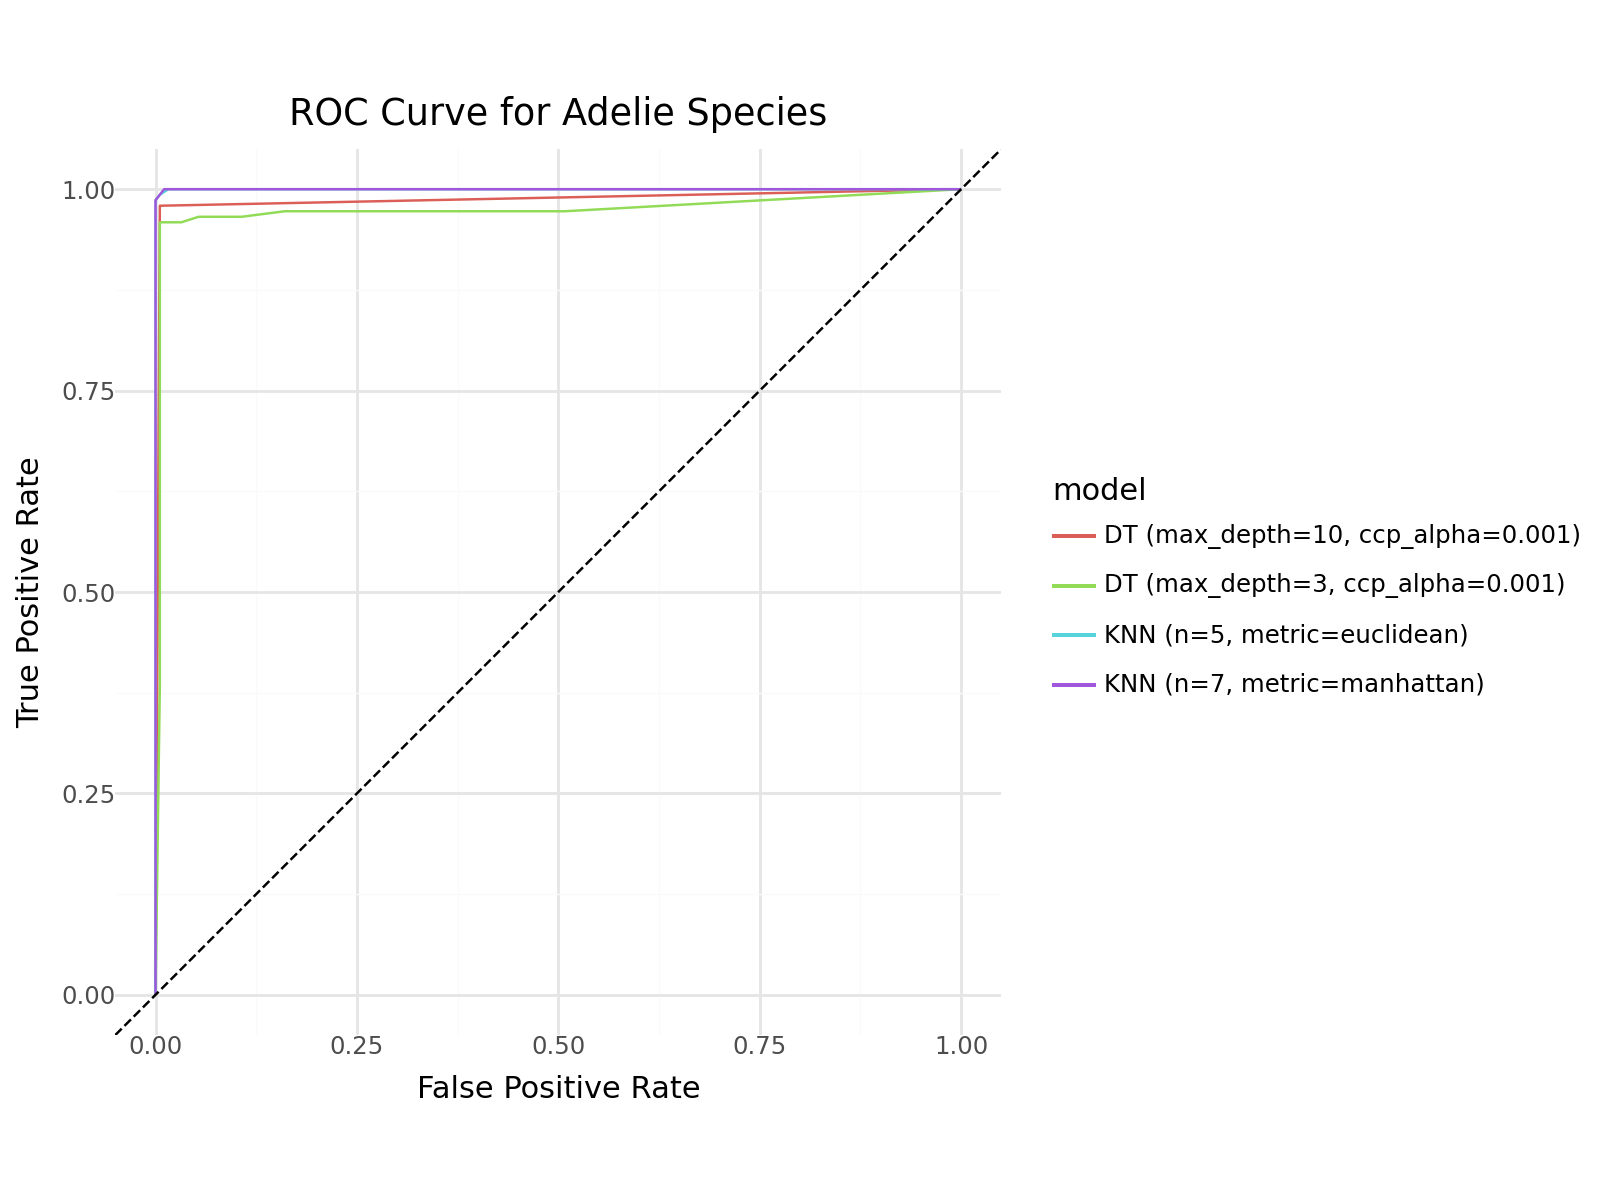

In [45]:
# Concatenate all ROC data into a single DataFrame
roc_df = pd.concat([df_knn7, df_knn5, df_dt3, df_dt10])

# Create the ROC plot using plotnine
(ggplot(roc_df, aes("FPR", "TPR", color="model"))
 + geom_path()
 + geom_abline(linetype="dashed")
 + coord_equal()
 + labs(title="ROC Curve for Adelie Species", x="False Positive Rate", y="True Positive Rate")
 + theme_minimal()
 + theme(figure_size=(8, 6)))